# NB02: Real Components and Functors Tour

This notebook is a guided tour of RELIC's real scientific components. You will learn:

1. How the parameter database, the variable contracts, the SSOT variable catalog and the CLI are reached from Python
2. How a real Functor (`FarquharPhotosynthesis`) runs inside `RELICSimulator`, and why every initial-state variable needs declared units
3. The four abstraction pillars (PhysicalField, BiologicalProcess, TransportMechanism, ScaleCoupling) and the bridge class each Functor inherits
4. How `FunctorMetadata` declares inputs, outputs, spatial scale and variable kind, and how `get_dependencies()` declares execution dependencies
5. How to find the Functor that wrote a state variable (`get_variable_provenance`) and how metadata inputs and outputs connect Functors

**Prerequisites:** NB01 (Minimal Run).

**Theory Reference:** `docs/source/coertheory.md`, Section 0.4 (structural, constraint and interpretable layers), Section 3.2 (semantic single source of truth: parameter maps and variable contracts) and Section 4.1 (tier separation).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


### Functor Abstraction (Mathematical Foundation)

Every scientific process in RELIC is a **Functor**. Its kernel is
`forward(state, time, dt, **kwargs)`, a map
$\mathcal{F}: \mathcal{S} \times T \times \mathbb{R}^+ \to \Delta\mathcal{S}$
from the current state, time and step to a dictionary of state updates
(`UpdateItem` values). The simulator calls the Functor object, so each call
runs `FunctorBase.__call__`: it prepares and validates the input state,
runs and times `forward`, and then applies the local conservation hook and
the framework validation rules to the returned updates. The four pillars of
abstraction are:

| Pillar | Mathematical Object |
|--------|---------------------|
| $\texttt{PhysicalField}$ | Field over domain $\Omega$: $\phi: \Omega \to \mathbb{R}^k$ |
| $\texttt{BiologicalProcess}$ | Rate law: $r(\mathbf{x}, \theta) \in \mathbb{R}^m$ |
| $\texttt{TransportMechanism}$ | Flux divergence: $\nabla \cdot \mathbf{J}(\mathbf{x})$ |
| $\texttt{ScaleCoupling}$ | Scale transfer: $\langle \cdot \rangle_\lambda$ |

Each Functor declares its **FunctorMetadata**, including
`input_variables`, `output_variables`, `spatial_scale`, and `variable_kind`.
Execution dependencies are not a metadata field: `get_dependencies()` returns
them. The bridge default returns `self._merge_declared_dependencies()`, which
returns only the names declared on the instance through
`config["dependencies"]`, `set_dependencies(...)` and `add_dependency(...)`.
A Functor with a class-level static declaration overrides
`get_dependencies()` and returns `self._merge_declared_dependencies(static)`,
which merges the static names with the instance names. `NitrogenCycling`,
for example, passes its enabled subprocess Functors as `static`.

The **Functor Lifecycle Chain** requires:
$$
\text{Abstraction Contract} \to \text{Bridge Class} \to \text{FunctorBase} \to \text{Parameter System}
$$

Any module that fails this chain is **non-compliant** and will be rejected.

## Setup and Imports

The first code cell locates the repository root. The next cell reaches four RELIC components:

- the global ParameterManager: it reads the namespace `biosphere.photosynthesis.surrogate` with `get_namespace_parameters`, which loads the whole namespace from the database (`manager.list()` only filters keys that are already loaded);
- the SCM variable contracts, loaded through `load_contract_registry()`, the single loader of the packaged contracts;
- the SSOT variable catalog (`SSOTCatalog.from_parameter_manager`). Loading raises `ValueError` when two declarations of one variable contradict each other or when an alias is claimed twice, so a loaded catalog carries no conflict list. An entry's `spatial_basis` states its spatial representation (for GPP: `area_density`);
- the `relic` CLI parser. Importing `relic.interfaces.cli.main` leaves logging
  unchanged; its command-line `main()` configures the handler. A notebook
  may configure logging explicitly.

The cell after it runs the real `FarquharPhotosynthesis` Functor for one 1800 s step. `initialize_state` accepts only variables with declared units, taken from the SCM contract, the SSOT catalog, `validation.numerical.state_variable_bounds`, or the simulator setting `state_units` (for tutorial-only variables); a variable without declared units raises `ValueError`. Every variable used here has an SCM contract, and the cell prints the declared unit of each one.

In [1]:
from __future__ import annotations

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import asyncio
import os
import sys
from pathlib import Path

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))

def find_repo_root() -> Path:
    candidates = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the RELIC project root. Set RELIC_PROJECT_ROOT if needed.")

REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print(f"[OK] REPO_ROOT = {REPO_ROOT}")


[OK] REPO_ROOT = <RELIC_ROOT>


In [2]:
import torch

from relic.parameters import get_global_manager
from relic.contracts import load_contract_registry
from relic.orchestration.ssot_catalog import SSOTCatalog
from relic.interfaces.cli.main import create_main_parser
from relic.core import RELICSimulator
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

manager = get_global_manager()
assert manager is not None, "Global ParameterManager is required."

# get_namespace_parameters loads the whole namespace from the parameter database;
# manager.list() only filters keys that are already loaded in this process.
surrogate_namespace = "biosphere.photosynthesis.surrogate"
surrogate_keys = sorted(manager.get_namespace_parameters(surrogate_namespace))
max_gpp_key = f"{surrogate_namespace}.max_gpp_rate"
max_gpp_rate = manager.get(max_gpp_key, required=True)
max_gpp_units = manager.get_parameter(max_gpp_key).units

# load_contract_registry() is the single loader of the packaged SCM contracts;
# it is strict (an unreadable, schema-invalid or duplicate contract raises ValueError).
registry = load_contract_registry()
soil_moisture_contract = registry.get_contract("soil_moisture")
assert soil_moisture_contract is not None, "soil_moisture contract must exist."

# Loading raises ValueError on contradicting declarations or alias conflicts.
catalog = SSOTCatalog.from_parameter_manager(manager)
gpp_entry = catalog.get("gross_primary_productivity")
assert gpp_entry is not None, "gross_primary_productivity must exist in SSOTCatalog."

parser = create_main_parser()
subparsers_action = next(
    action for action in parser._actions if hasattr(action, "choices") and action.choices
)
subcommands = sorted(list(subparsers_action.choices.keys()))
required_subcommands = {
    "params",
    "optimization",
    "data",
    "compute",
    "stochastic",
    "orchestration",
    "healthcheck",
}
assert required_subcommands.issubset(set(subcommands)), "CLI subcommands are incomplete."

component_summary = {
    "parameter_namespace": surrogate_namespace,
    "parameter_key_count": len(surrogate_keys),
    "sample_parameter": {
        "key": max_gpp_key,
        "value": float(max_gpp_rate),
        "units": max_gpp_units,
    },
    "contract_registry": {
        "variable_count": len(registry.list_variables()),
        "domain_count": len(registry.list_domains()),
        "sample_contract": {
            "variable": soil_moisture_contract.variable,
            "units": soil_moisture_contract.udunits,
            "owner": soil_moisture_contract.owner,
            "writers": soil_moisture_contract.writers,
        },
    },
    "ssot_catalog": {
        "sample_entry": {
            "name": gpp_entry.name,
            "standard_name": gpp_entry.standard_name,
            "units": gpp_entry.units,
            "spatial_basis": gpp_entry.spatial_basis.value,
        },
    },
    "cli": {
        "subcommands": subcommands,
    },
}

print(f"[OK] Parameter keys in {surrogate_namespace} = {len(surrogate_keys)}")
print(f"[OK] {max_gpp_key} = {float(max_gpp_rate):.3e} {max_gpp_units}")
print(f"[OK] Contract variables loaded = {len(registry.list_variables())}")
print(
    f"[OK] SSOT entry {gpp_entry.name}: units = {gpp_entry.units}, "
    f"spatial_basis = {gpp_entry.spatial_basis.value}"
)
print(f"[OK] CLI subcommands = {', '.join(subcommands)}")

component_summary

[OK] Parameter keys in biosphere.photosynthesis.surrogate = 8
[OK] biosphere.photosynthesis.surrogate.max_gpp_rate = 2.500e-05 kg C m-2 s-1
[OK] Contract variables loaded = 473
[OK] SSOT entry gross_primary_productivity: units = kg C m-2 s-1, spatial_basis = area_density
[OK] CLI subcommands = compute, data, graph, health, healthcheck, opt, optimization, orchestration, params, stoch, stochastic


{'parameter_namespace': 'biosphere.photosynthesis.surrogate',
 'parameter_key_count': 8,
 'sample_parameter': {'key': 'biosphere.photosynthesis.surrogate.max_gpp_rate',
  'value': 2.5e-05,
  'units': 'kg C m-2 s-1'},
 'contract_registry': {'variable_count': 473,
  'domain_count': 4,
  'sample_contract': {'variable': 'soil_moisture',
   'units': 'm3 m-3',
   'owner': None,
   'writers': ['bucket_soil_moisture',
    'richards_soil_moisture',
    'soil_water_transport',
    'observation_state_feedback']}},
 'ssot_catalog': {'sample_entry': {'name': 'gross_primary_productivity',
   'standard_name': 'gross_primary_productivity',
   'units': 'kg C m-2 s-1',
   'spatial_basis': 'area_density'}},
 'cli': {'subcommands': ['compute',
   'data',
   'graph',
   'health',
   'healthcheck',
   'opt',
   'optimization',
   'orchestration',
   'params',
   'stoch',
   'stochastic']}}

In [3]:
# References:
# - Farquhar, von Caemmerer and Berry (1980), Planta 149, 78-90.
# - relic/scientific/biosphere/photosynthesis/farquhar.py (FarquharPhotosynthesis)
# - docs/source/theory/photosynthesis.md
# - relic/core/simulator/state_init.py (declared-units rule of initialize_state)
# Mathematical expression (C3 path of the real Functor):
#   A_gross = min(A_c, A_j) * f_w * f_T * f_O3 * f_vpd,   f_vpd = 1 / (1 + D / D0)
#   A_net   = A_gross - R_d * f_w
#   canopy scaling: X_canopy = X_leaf * L_eff for X in {A_gross, A_net, R_d, J, A_j},
#     L_eff = (1 - exp(-k * LAI)) / k; Jmax (diagnostics.photosynthesis.jmax_actual)
#     is emitted as the unscaled leaf value
#   GPP     = A_gross * M_C * 1e-6 [mol umol-1] * 1e-3 [kg g-1]
# Parameter meanings:
#   A_c, A_j: Rubisco- and RuBP-regeneration-limited rates; R_d: dark respiration;
#   f_w, f_T, f_O3: water, temperature and ozone stress factors; D: vapor pressure deficit;
#   D0: VPD response scale; k: light extinction coefficient; LAI: leaf area index;
#   M_C: molar mass of carbon from the physical-constants SSOT;
#   J: electron transport rate; Jmax: its temperature-adjusted maximum.
#   All parameters come from the ParameterManager, not from this notebook:
#   vcmax25, jmax25, rd25, k and the other biochemical parameters from the
#   namespace biosphere.photosynthesis, rd_q10 from biosphere.respiration and
#   D0 from validation.numerical.vpd_response_d0.
# Units: A_gross, A_net, R_d [umol CO2 m-2 s-1]; GPP [kg C m-2 s-1]; D, D0 [Pa];
#   M_C [g mol-1]; J, Jmax [umol e- m-2 s-1]; stress factors, k [1]; LAI [m2 m-2].
# Domain/constraints: stress factors in [0, 1]; the Ci argument of A_c and A_j is the
#   atmospheric_co2_ppm input (this Functor has no intercellular CO2 model).
# Sign convention: positive A is net CO2 uptake by the canopy.

simulator_config = {
    "time_step": 1800.0,
    "max_time": 1800.0,
    "allow_bootstrap_modules": False,
    "enable_bootstrap_modules": False,
    "enable_auto_scale": False,
    "strict_scale_detection": False,
    "conservation_checks": False,
    "strict_conservation_enabled": False,
    "strict_dependencies": False,
    "device": "cpu",
}

initial_state = {
    "air_temperature": torch.tensor(298.15, dtype=torch.float32),         # K
    "atmospheric_co2_ppm": torch.tensor(410.0, dtype=torch.float32),      # umol mol-1
    "ppfd": torch.tensor(1200.0, dtype=torch.float32),                    # umol photons m-2 s-1
    "vapor_pressure_deficit": torch.tensor(1000.0, dtype=torch.float32),  # Pa (1 kPa)
    "vcmax_scaling": torch.tensor(1.0, dtype=torch.float32),              # 1
    "jmax_scaling": torch.tensor(1.0, dtype=torch.float32),               # 1
    "water_stress_factor": torch.tensor(1.0, dtype=torch.float32),        # 1
    "temperature_stress_factor": torch.tensor(1.0, dtype=torch.float32),  # 1
    "ozone_stress_factor": torch.tensor(1.0, dtype=torch.float32),        # 1
    "leaf_area_index": torch.tensor(3.0, dtype=torch.float32),            # m2 m-2
}

# initialize_state rejects any variable without declared units. Every variable
# above has an SCM contract; a tutorial-only variable would need the simulator
# setting "state_units": {"variable_name": "unit"}.
declared_units = {name: registry.get_contract(name).udunits for name in initial_state}
for name, units in declared_units.items():
    print(f"  declared units: {name} -> {units}")

simulator = RELICSimulator(config=simulator_config)
simulator.initialize_state(initial_state)

real_functor = FarquharPhotosynthesis(
    name="farquhar_photosynthesis",
    enable_gpu=False,
    device=torch.device("cpu"),
)
# The constructor declares the canonical VPD and PPFD providers
# ("environmental_forcing", "atmospheric_radiation") on the instance. This cell
# supplies vapor_pressure_deficit and ppfd directly in the initial state, so the
# instance declaration is replaced by an empty one through the public API.
default_dependencies = real_functor.get_dependencies()
real_functor.set_dependencies([])
assert real_functor.get_dependencies() == []
simulator.register_functor(real_functor, execution_group="fast")
updates = simulator.step(dt=1800.0)
state = simulator.state_manager.get_current_state()
summary = simulator.get_functor_summary()["farquhar_photosynthesis"]
provenance = simulator.get_variable_provenance("gross_primary_productivity")

required_outputs = {
    "gross_primary_productivity",
    "gross_photosynthesis",
    "net_photosynthesis",
    "diagnostics.photosynthesis.dark_respiration",
    "electron_transport_rate",
}
assert required_outputs.issubset(set(updates.keys())), "Real functor outputs are incomplete."
assert "diagnostics.photosynthesis.dark_respiration" in updates, "Dark-respiration diagnostic is missing."

gpp = float(state["gross_primary_productivity"].detach())
dark_respiration = float(updates["diagnostics.photosynthesis.dark_respiration"].detach())
net_photosynthesis = float(state["net_photosynthesis"].detach())
gross_photosynthesis = float(state["gross_photosynthesis"].detach())
jmax_actual = float(updates["diagnostics.photosynthesis.jmax_actual"].detach())
electron_transport = float(updates["electron_transport_rate"].detach())

assert gpp > 0.0, "gpp must be positive."
assert dark_respiration >= 0.0, "dark_respiration must be non-negative."
# The emitted dark_respiration diagnostic already includes f_w and L_eff, so
# A_net = A_gross - R_d holds for any f_w: it is the carbon_boundary identity
# that the Functor's check_conservation_laws evaluates.
assert abs(net_photosynthesis - (gross_photosynthesis - dark_respiration)) <= 1.0e-4 * abs(gross_photosynthesis)
expected_gpp = gross_photosynthesis * float(torch.as_tensor(real_functor.carbon_molar_mass_g_mol)) * 1.0e-9
assert abs(gpp - expected_gpp) <= max(1.0e-12, 1.0e-6 * abs(expected_gpp)), "Molar-to-carbon-mass GPP conversion failed."
assert summary["spatial_scale"] == "patch", "Unexpected spatial_scale for real functor."
assert summary["variable_kind"] == "flux", "Unexpected variable_kind for real functor."
assert len(provenance) >= 1, "Provenance must not be empty."

simulation_summary = {
    "declared_units": declared_units,
    "default_dependencies": default_dependencies,
    "update_keys": sorted(list(updates.keys())),
    "gross_photosynthesis": gross_photosynthesis,
    "gpp": gpp,
    "dark_respiration": dark_respiration,
    "net_photosynthesis": net_photosynthesis,
    "summary_spatial_scale": summary["spatial_scale"],
    "summary_variable_kind": summary["variable_kind"],
    "diagnostic_respiration_present": "diagnostics.photosynthesis.dark_respiration" in updates,
    "provenance_count": len(provenance),
}

print(f"[OK] Default dependencies = {default_dependencies}; after set_dependencies([]) = {real_functor.get_dependencies()}")
print(f"[OK] Gross photosynthesis = {gross_photosynthesis:.4f} umol CO2 m-2 s-1")
print(f"[OK] Dark respiration = {dark_respiration:.4f} umol CO2 m-2 s-1")
print(f"[OK] Net photosynthesis = {net_photosynthesis:.4f} umol CO2 m-2 s-1")
print(f"[OK] jmax_actual (leaf value, not canopy scaled) = {jmax_actual:.2f} umol e- m-2 s-1")
print(f"[OK] electron_transport_rate (canopy scaled with L_eff) = {electron_transport:.2f} umol e- m-2 s-1")
print(f"[OK] GPP = {gpp:.4e} kg C m-2 s-1")
print(f"[OK] Real functor spatial_scale = {summary['spatial_scale']}")
print(f"[OK] Real functor variable_kind = {summary['variable_kind']}")
print("[OK] The state-level carbon flux is 'gross_primary_productivity'; dark respiration is a diagnostics.* output only.")
print(f"[OK] Provenance entries for gross_primary_productivity = {len(provenance)}")
print("[OK] This cell runs the canonical Farquhar Functor, not the surrogate photosynthesis module.")

simulation_summary

  declared units: air_temperature -> K
  declared units: atmospheric_co2_ppm -> umol mol-1
  declared units: ppfd -> umol photons m-2 s-1
  declared units: vapor_pressure_deficit -> Pa
  declared units: vcmax_scaling -> 1
  declared units: jmax_scaling -> 1
  declared units: water_stress_factor -> dimensionless
  declared units: temperature_stress_factor -> dimensionless
  declared units: ozone_stress_factor -> dimensionless
  declared units: leaf_area_index -> m2 m-2


[OK] Default dependencies = ['environmental_forcing', 'atmospheric_radiation']; after set_dependencies([]) = []
[OK] Gross photosynthesis = 21.0418 umol CO2 m-2 s-1
[OK] Dark respiration = 1.8645 umol CO2 m-2 s-1
[OK] Net photosynthesis = 19.1773 umol CO2 m-2 s-1
[OK] jmax_actual (leaf value, not canopy scaled) = 148.60 umol e- m-2 s-1
[OK] electron_transport_rate (canopy scaled with L_eff) = 189.27 umol e- m-2 s-1
[OK] GPP = 2.5273e-07 kg C m-2 s-1
[OK] Real functor spatial_scale = patch
[OK] Real functor variable_kind = flux
[OK] The state-level carbon flux is 'gross_primary_productivity'; dark respiration is a diagnostics.* output only.
[OK] Provenance entries for gross_primary_productivity = 2
[OK] This cell runs the canonical Farquhar Functor, not the surrogate photosynthesis module.


{'declared_units': {'air_temperature': 'K',
  'atmospheric_co2_ppm': 'umol mol-1',
  'ppfd': 'umol photons m-2 s-1',
  'vapor_pressure_deficit': 'Pa',
  'vcmax_scaling': '1',
  'jmax_scaling': '1',
  'water_stress_factor': 'dimensionless',
  'temperature_stress_factor': 'dimensionless',
  'ozone_stress_factor': 'dimensionless',
  'leaf_area_index': 'm2 m-2'},
 'default_dependencies': ['environmental_forcing', 'atmospheric_radiation'],
 'update_keys': ['diagnostics.photosynthesis.dark_respiration',
  'diagnostics.photosynthesis.jmax_actual',
  'diagnostics.photosynthesis.limitation_factor',
  'diagnostics.photosynthesis.pathway_type',
  'diagnostics.photosynthesis.transport_limited',
  'electron_transport_rate',
  'gross_photosynthesis',
  'gross_primary_productivity',
  'net_photosynthesis'],
 'gross_photosynthesis': 21.041805267333984,
 'gpp': 2.527331162127666e-07,
 'dark_respiration': 1.864487648010254,
 'net_photosynthesis': 19.177318572998047,
 'summary_spatial_scale': 'patch',
 '

## Anthroposphere Module

The **anthroposphere** package (`relic.scientific.anthroposphere`) models
human impacts on biogeochemical cycles:

- **Land use**: `LandUseTransitions` (continuous-time Markov chain over LUH2-class land-use categories) and `LandUseParameterMapping`
- **Emissions**: `SpeciesMapper` maps emitted species to chemical-mechanism species and converts their units. `SectorAllocation` is exported only by the subpackage `relic.scientific.anthroposphere.emissions`, not by the package itself. `EmissionInventory` and `AtmosphereCoupling` are fail-closed nodes: their constructors raise `RuntimeError` (the `EmissionInventory` error is shown further below)
- **Management**: fertilization, irrigation, tillage, harvest, grazing and fire Functors, plus the `ManagementCoordinator`

`LandUseTransitions`, `LandUseParameterMapping`, `SectorAllocation`,
`SpeciesMapper` and the management Functors declare `SpatialScale.GRID_CELL`
in their metadata. `AnthroposphereInterfaceMapping` (CF metadata mapping) also
fails closed at construction. The next cell lists the public names of the
package and checks where `SectorAllocation` is exported.

In [4]:
# References:
# - relic/scientific/anthroposphere/__init__.py (public API of the package)
# - relic/scientific/anthroposphere/inventory.py (EmissionInventory, fail-closed)
# - relic/scientific/anthroposphere/management/ (management Functors and coordinator)
# This cell lists the public names of the package and checks where
# SectorAllocation is exported; it runs no process.
# EmissionInventory documents the expression it would need, but its constructor
# raises RuntimeError because the target-domain fraction beta and the grid
# allocation P have no executable binding:
#   F[s,k,i,t] = E_global[s,k] * beta[s,k,D] * T[s,k,t] * P[s,k,i|D] / (Y * seconds_per_day * A[i])
# Where:
#   E_global = global annual inventory mass for sector s and species k [kg inventory-year-1]
#   beta     = sector/species fraction assigned to the target domain D [1]
#   T        = calendar-normalized temporal factor [1]
#   P        = within-domain allocation to cell i, sum_i P = 1 [1]
#   Y        = simulator-calendar year length [day inventory-year-1]
#   A[i]     = target cell area [m2]; F = surface source rate [kg m-2 s-1]

import relic.scientific.anthroposphere as anthro

# Inspect available anthroposphere components
anthro_components = [
    name for name in dir(anthro) if not name.startswith("_")
]
print("Anthroposphere components:", anthro_components[:10])
print(f"Total public API entries: {len(anthro_components)}")
assert len(anthro_components) > 0, "Anthroposphere module should have components"
print("[OK] Anthroposphere module accessible")

# SectorAllocation is exported by the emissions subpackage only; its import is
# commented out in relic/scientific/anthroposphere/__init__.py.
from relic.scientific.anthroposphere.emissions import SectorAllocation

assert not hasattr(anthro, "SectorAllocation"), "SectorAllocation is not a package-level name."
print(f"SectorAllocation in relic.scientific.anthroposphere: {hasattr(anthro, 'SectorAllocation')}")
print(f"SectorAllocation imported from relic.scientific.anthroposphere.emissions: {SectorAllocation.__module__}")

Anthroposphere components: ['AnthroposphereInterfaceMapping', 'ApplicationMethod', 'ApplicationTiming', 'AtmosphereCoupling', 'ChemicalMechanism', 'ConflictResolution', 'CoordinationMode', 'CoordinationResult', 'CropType', 'EmissionInventory']
Total public API entries: 53
[OK] Anthroposphere module accessible
SectorAllocation in relic.scientific.anthroposphere: False
SectorAllocation imported from relic.scientific.anthroposphere.emissions: relic.scientific.anthroposphere.emissions.sector_allocation


## Real Biosphere Functor: FarquharFunctor

`FarquharFunctor` is the name `relic.scientific` exports for
`FarquharPhotosynthesis`, the Farquhar-von Caemmerer-Berry (FvCB) model of C3
photosynthesis (Farquhar et al., 1980). The C3 path computes

$$
A_n = \min(A_c,\; A_j)\, f_w f_T f_{O_3} f_{vpd} - R_d f_w
$$

where:
- $A_c = V_{c,\max} \frac{C_i - \Gamma^*}{C_i + K_c(1 + O/K_o)}$ (Rubisco-limited)
- $A_j = J \frac{C_i - \Gamma^*}{4C_i + 8\Gamma^*}$ (RuBP-regeneration-limited)
- $f_{vpd} = 1/(1 + D/D_0)$; $f_w$, $f_T$, $f_{O_3}$ are the water, temperature and ozone stress factors
- $R_d$ = dark respiration [$\mu$mol CO$_2$ m$^{-2}$ s$^{-1}$]

The C3 path has no triose-phosphate-utilization limit. The $C_i$ argument is
the `atmospheric_co2_ppm` input; the Functor has no intercellular CO$_2$ model
(`docs/source/theory/photosynthesis.md`). The gross and net assimilation rates,
$R_d$, the electron transport rate $J$ and $A_j$ are scaled from leaf to canopy with
$L_{eff} = (1 - e^{-k\,LAI})/k$. The diagnostic
`diagnostics.photosynthesis.jmax_actual` is the unscaled leaf value: the simulation cell prints it separately from the canopy-scaled
`electron_transport_rate`, both in umol e- m$^{-2}$ s$^{-1}$.
`gross_primary_productivity` converts the gross molar rate to
kg C m$^{-2}$ s$^{-1}$. The C4 path
(Collatz et al., 1992) takes a three-way minimum instead.

### Functor Discovery: `FUNCTOR_REGISTRY`

`relic.scientific.FUNCTOR_REGISTRY` maps names to `"module:Class"` path strings.
Importing `relic.scientific` runs `register_all_functors()` once; it imports every
module of the scientific subpackages except the command-line entry modules
(`*_cli.py`, which define no Functor) and registers every `FunctorBase` subclass
found there (this includes
the four bridge classes, which the scientific modules import, and base classes
such as `PhenologyBase`), so the registry is complete before any lookup. Each class is
registered under its name (`FUNCTOR_NAME`, a class-level `metadata.name`, or the
class name), the lowercase form of that name, and the snake_case form of the
class name. `get_functor_path(name)` tries the name as given, lowercased and in
snake_case, and raises `KeyError` when nothing matches. Binding a name to a
second class raises `ValueError`.

The registry resolves Functor names written in configuration: `GraphExecutor`
uses it for a node `class_type` without a module path that its node registry
does not resolve, and the simulator's
test-only bootstrap (`enable_bootstrap_modules`) uses it for the requested
Functor name. `RELICSimulator.register_functor()` takes a Functor instance and
does not use the registry. A registered class is not necessarily runnable:
`EmissionInventory` and `IsotopeHeartbeatFunctor` are registered but fail closed
at construction.

In [5]:
# FUNCTOR_REGISTRY: name -> "module:Class" path string, filled once when
# relic.scientific is imported (register_all_functors()).
# Consumers: GraphExecutor._resolve_functor_class (relic/orchestration/executor.py)
# and the simulator's test-only bootstrap (relic/core/simulator/state_init.py).
# Reference: architecture_overview.md, Section 7 (Registration mechanism).

from collections import Counter

from relic.scientific import FUNCTOR_REGISTRY, get_functor_path, list_available_functors

# Each class is registered under three keys; the key that starts with an
# uppercase letter is its class name, so it selects one key per class.
class_paths = {key: path for key, path in FUNCTOR_REGISTRY.items() if key[0].isupper()}
assert len(class_paths) == len(set(FUNCTOR_REGISTRY.values())), "Expected one class-name key per registered class."
print(f"Registry keys = {len(FUNCTOR_REGISTRY)}, registered classes = {len(class_paths)}")


def registry_package(path: str) -> str:
    # Sphere package for relic.scientific classes, module package otherwise.
    module_parts = path.split(":")[0].split(".")
    if module_parts[:2] == ["relic", "scientific"]:
        return f"relic.scientific.{module_parts[2]}"
    return ".".join(module_parts[:-1])


for package, count in sorted(Counter(registry_package(path) for path in class_paths.values()).items()):
    print(f"  {package}: {count}")

# The three registered spellings resolve to the same path.
for name in ("FarquharPhotosynthesis", "farquharphotosynthesis", "farquhar_photosynthesis"):
    print(f"get_functor_path({name!r}) -> {get_functor_path(name)}")

# An unknown name raises KeyError (no scan, no fallback).
try:
    get_functor_path("NoSuchFunctor")
except KeyError as exc:
    missing_name_error = str(exc)
else:
    raise AssertionError("get_functor_path must raise KeyError for an unknown name.")
print(f"get_functor_path('NoSuchFunctor') -> KeyError: {missing_name_error}")

# list_available_functors() returns a fixed list of nine names exported by
# relic.scientific: five aliases (for example FarquharFunctor for
# FarquharPhotosynthesis) and four classes under their own names
# (RadiationFunctor, TurbulenceFunctor, PenmanMonteithET, RichardsSoilMoisture).
# It does not read the registry.
available = list_available_functors()
print(f"\nlist_available_functors(): {available}")
print("[OK] FUNCTOR_REGISTRY & discovery API demonstrated")

Registry keys = 279, registered classes = 93
  relic.core.functor: 4
  relic.scientific.anthroposphere: 14
  relic.scientific.atmosphere: 11
  relic.scientific.biosphere: 23
  relic.scientific.hydrosphere: 13
  relic.scientific.isotopes: 1
  relic.scientific.pedosphere: 24
  relic.scientific.transport: 3
get_functor_path('FarquharPhotosynthesis') -> relic.scientific.biosphere.photosynthesis.farquhar:FarquharPhotosynthesis
get_functor_path('farquharphotosynthesis') -> relic.scientific.biosphere.photosynthesis.farquhar:FarquharPhotosynthesis
get_functor_path('farquhar_photosynthesis') -> relic.scientific.biosphere.photosynthesis.farquhar:FarquharPhotosynthesis
get_functor_path('NoSuchFunctor') -> KeyError: "No functor is registered under the name 'NoSuchFunctor'."

list_available_functors(): {'biosphere': ['FarquharFunctor', 'MaintenanceRespirationFunctor', 'BVOCEmissionFunctor'], 'atmosphere': ['RadiationFunctor', 'TurbulenceFunctor'], 'hydrosphere': ['PenmanMonteithET', 'RichardsSoilMo

In [6]:
# References:
# - Farquhar et al. (1980) Planta 149:78-90
# - relic/scientific/biosphere/photosynthesis/farquhar.py
# - relic/parameters/database_manager.py (load order: relic tier, then calibrated
#   tier; a later entry of the same key takes precedence)
#
# Mathematical expression (C3 path, see the markdown above):
#   A_n = min(A_c, A_j) * f_w * f_T * f_O3 * f_vpd - R_d * f_w
# Parameter meanings (ParameterManager namespace biosphere.photosynthesis):
#   vcmax25: maximum carboxylation rate of Rubisco at 25 C
#   jmax25: maximum electron transport rate at 25 C
#   rd25: dark respiration rate at 25 C
# Units:
#   vcmax25 and rd25 [umol CO2 m-2 s-1]; jmax25 [umol e- m-2 s-1]; the cell prints
#   the units of each ParameterSpec.
# Domain/constraints:
#   The constructor arguments vcmax25, jmax25 and rd25 override the database
#   values; this cell passes none of them, so the Functor holds the values the
#   global ParameterManager resolves. The cell prints the file each value comes from.
# Sign convention:
#   Positive A_n is net CO2 uptake; the three parameters are positive rates.

import inspect
import torch

from relic.scientific import FarquharFunctor

# Instantiate with the parameters of the YAML database
farquhar = FarquharFunctor(
    name="demo_farquhar",
    enable_gpu=False,
    device=torch.device("cpu"),
)
print(f"Functor: {farquhar.name}")
print(f"Type: {type(farquhar).__name__}")

# Inspect metadata and declarations
meta = farquhar.metadata
print(f"Input variables: {meta.input_variables}")
print(f"Output variables: {meta.output_variables}")
print(f"Required inputs: {farquhar.get_required_inputs()}")
print(f"Declared dependencies: {farquhar.get_dependencies()}")
for parameter_name in ("vcmax25", "jmax25", "rd25"):
    spec = manager.get_parameter(f"biosphere.photosynthesis.{parameter_name}")
    source_file = Path(spec.provenance["source_file"]).resolve().relative_to(REPO_ROOT).as_posix()
    print(
        f"{parameter_name} = {float(getattr(farquhar, parameter_name).detach()):.3f} {spec.units} "
        f"(source: {source_file})"
    )

# Show constructor parameters
sig = inspect.signature(FarquharFunctor.__init__)
params = [p for p in sig.parameters if p != "self"]
print(f"Constructor params: {params}")
print("[OK] FarquharFunctor instantiated with the parameters of the database.")

Functor: demo_farquhar
Type: FarquharPhotosynthesis
Input variables: ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'vcmax_scaling', 'vpmax_scaling', 'jmax_scaling', 'water_stress_factor', 'temperature_stress_factor', 'ozone_stress_factor', 'leaf_area_index']
Output variables: ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limited', 'diagnostics.photosynthesis.jmax_actual', 'diagnostics.photosynthesis.limitation_factor', 'diagnostics.photosynthesis.pathway_type']
Required inputs: ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'leaf_area_index']
Declared dependencies: ['environmental_forcing', 'atmospheric_radiation']
vcmax25 = 75.300 umol CO2 m-2 s-1 (source: relic/parameters/database/calibrated/site_specific/harvard_forest_photosynthesis.yaml)
jmax25 = 148.600 umol e- m-2 s-1 (source: r

In [7]:
# References:
# - Allen et al. (1998), FAO Irrigation and Drainage Paper 56, Eq. 11.
# - relic/scientific/atmosphere/environmental_forcing.py (EnvironmentalForcingFunctor)
# Mathematical expression:
#   T_C = T_K - T0
#   e_s = e_s0 * exp(a * T_C / (T_C + b))        [kPa]
#   VPD = max(e_s * (1 - RH), 0), converted to Pa
# Parameter meanings:
#   T_K: air temperature; T0: Celsius-to-Kelvin offset (physical-constants SSOT);
#   e_s0, a, b: Magnus coefficients (ParameterManager namespace
#   atmosphere.environmental_forcing.vpd); RH: relative humidity.
# Units: T_K, T0 [K]; e_s0 [kPa]; a [1]; b [degC]; RH [1]; VPD [Pa].
# Domain/constraints: RH must lie in [0, 1]; inputs must be finite floating tensors.
# Sign convention: VPD >= 0 (clamped at zero); it is a derived forcing field, not a flux.
# The Functor object is called, so FunctorBase.__call__ validates the input
# state, runs forward(), and then applies the local conservation hook and the
# framework validation rules to the returned updates.

from relic.scientific.atmosphere.environmental_forcing import EnvironmentalForcingFunctor

forcing_functor = EnvironmentalForcingFunctor(device=torch.device("cpu"))
forcing_state = {
    "air_temperature": torch.tensor(298.15, dtype=torch.float32),  # K
    "relative_humidity": torch.tensor(0.60, dtype=torch.float32),  # 1
}
forcing_updates = forcing_functor(forcing_state, time=0.0, dt=3600.0)
vpd_update = forcing_updates["vapor_pressure_deficit"]
vapor_pressure_deficit = vpd_update.value

# Independent recomputation with the Functor's own coefficients (1000 Pa per kPa).
temperature_c = forcing_state["air_temperature"] - forcing_functor.celsius_to_kelvin
expected_vpd_pa = (
    forcing_functor.es_coefficient
    * torch.exp(forcing_functor.vpd_a * temperature_c / (temperature_c + forcing_functor.vpd_b))
    * (1.0 - forcing_state["relative_humidity"])
    * 1000.0
)
assert sorted(forcing_updates.keys()) == ["vapor_pressure_deficit"], "The Functor emits exactly one output."
assert vpd_update.unit == "Pa", "vapor_pressure_deficit must be emitted in Pa."
assert torch.all(vapor_pressure_deficit >= 0), "vapor_pressure_deficit must be non-negative."
assert torch.allclose(vapor_pressure_deficit, expected_vpd_pa, rtol=1.0e-5), "VPD recomputation mismatch."

environmental_forcing_summary = {
    "update_keys": sorted(forcing_updates.keys()),
    "vapor_pressure_deficit": float(vapor_pressure_deficit),
    "units": vpd_update.unit,
    "magnus_coefficients": {
        "es0_kpa": forcing_functor.es_coefficient,
        "a": forcing_functor.vpd_a,
        "b_degc": forcing_functor.vpd_b,
    },
}

print(f"[OK] Environmental forcing outputs = {', '.join(sorted(forcing_updates.keys()))}")
print(f"[OK] VPD at 298.15 K and RH = 0.60: {float(vapor_pressure_deficit):.1f} {vpd_update.unit}")

environmental_forcing_summary

[OK] Environmental forcing outputs = vapor_pressure_deficit
[OK] VPD at 298.15 K and RH = 0.60: 1267.1 Pa


{'update_keys': ['vapor_pressure_deficit'],
 'vapor_pressure_deficit': 1267.1112060546875,
 'units': 'Pa',
 'magnus_coefficients': {'es0_kpa': 0.61080002784729,
  'a': 17.270000457763672,
  'b_degc': 237.3000030517578}}

## Anthroposphere: Management Functors

The `relic.scientific.anthroposphere` subpackage provides management-level
Functors that model human interventions in biogeochemical cycles. Key classes
and the bridge class each one inherits:

- **`ManagementCoordinator`** (`ScaleCouplingFunctor`): schedules management
  events (tillage, harvest, fertilization, fire and others), resolves conflicts
  between competing events and applies resource constraints.
- **`FireManagement`** (`BiologicalProcessFunctor`): prescribed burns and wildfire
  combustion of fuel carbon, with CO$_2$, CO, CH$_4$ and N$_2$O emission outputs.
- **`TillageManagement`** (`TransportMechanismFunctor`): tillage disturbance,
  residue incorporation, porosity and roughness modifiers and the tillage carbon
  export; decomposition and infiltration stay with their pedosphere and
  hydrosphere Functors.
- **`IrrigationManagement`** (`TransportMechanismFunctor`): irrigation demand from
  the soil-moisture deficit, application efficiency and water quotas, emitted as
  an irrigation water flux.
- **`EmissionInventory`** (`ScaleCouplingFunctor`): a fail-closed node. Its
  constructor raises `RuntimeError` (`[N] runtime_domain_unbound`) because the
  HTAPv3.2/EDGAR global totals have no executable target-domain fraction or grid
  binding, so it produces no emissions.

The bridge classes connect the four abstract pillars (PhysicalField,
BiologicalProcess, TransportMechanism, ScaleCoupling) to `FunctorBase`, as the
RELIC architecture requires. The next cell prints the first five classes of each method resolution order
and the required input declarations; it does not call a management kernel.
Coordinator execution also needs `evapotranspiration_flux`,
`precipitation_flux`, `field_capacity` and `wilting_point`. Fire needs
biomass, litter and fuel-moisture state; tillage needs soil temperature,
organic carbon and time-since-tillage state. Fire construction itself
requires `config["seed"]` in `[0, 2**63)`.

In [8]:
import torch
from relic.scientific.anthroposphere import (
    ManagementCoordinator,
    EventScheduler,
    FireManagement,
    HarvestManagement,
    TillageManagement,
    EmissionInventory,
    EventType, EventPriority,
    ManagementEvent,
)

# -- Instantiate the ManagementCoordinator (ScaleCouplingFunctor) --
coordinator = ManagementCoordinator()
print(f"ManagementCoordinator: {coordinator.name}")
print(f"  Base classes: {[b.__name__ for b in type(coordinator).__mro__[:5]]}")

# -- EventScheduler: manages priority-based event queuing --
scheduler = EventScheduler()
print(f"\nEventScheduler created: {type(scheduler).__name__}")

# -- FireManagement: construction requires an explicit Functor-owned substream seed --
fire_mgr = FireManagement(config={"seed": 7})
print(f"\nFireManagement: {fire_mgr.name}")
print(f"  Base classes: {[b.__name__ for b in type(fire_mgr).__mro__[:5]]}")

# -- TillageManagement (TransportMechanismFunctor) --
tillage_mgr = TillageManagement()
print(f"\nTillageManagement: {tillage_mgr.name}")
print(f"  Base classes: {[b.__name__ for b in type(tillage_mgr).__mro__[:5]]}")

# -- EmissionInventory: fail-closed node, the constructor raises RuntimeError --
try:
    EmissionInventory()
except RuntimeError as exc:
    emission_inventory_blocker = str(exc)
else:
    raise AssertionError("EmissionInventory must fail closed while its target-domain binding is unavailable.")
assert "[N] runtime_domain_unbound" in emission_inventory_blocker
print(f"\nEmissionInventory boundary: {emission_inventory_blocker}")

# Show available event types and priorities
print(f"\nEvent types: {[e.name for e in EventType]}")
print(f"Event priorities: {[e.name for e in EventPriority]}")

# Verify all Functors satisfy the architecture chain
from relic.core.functor import FunctorBase
for functor in [coordinator, fire_mgr, tillage_mgr]:
    assert isinstance(functor, FunctorBase), f"{functor.name} is not FunctorBase!"
assert issubclass(EmissionInventory, FunctorBase)
print("\n[OK] Executable anthroposphere Functors follow FunctorBase; the unbound inventory entry fails closed before side effects.")
for functor in (coordinator, fire_mgr, tillage_mgr):
    print(f"Required inputs before executing {functor.name}: {functor.get_required_inputs()}")
print("[OK] Constructor inspection only; no management kernel was executed.")


ManagementCoordinator: management_coordinator
  Base classes: ['ManagementCoordinator', 'NamespaceDefaultMixin', 'ScaleCouplingFunctor', 'BridgeParameterMixin', 'ScaleCoupling']

EventScheduler created: EventScheduler

FireManagement: fire_management
  Base classes: ['FireManagement', 'FunctorSubstreamMixin', 'NamespaceDefaultMixin', 'BiologicalProcessFunctor', 'BridgeParameterMixin']

TillageManagement: tillage_management
  Base classes: ['TillageManagement', 'TransportMechanismFunctor', 'BridgeParameterMixin', 'TransportMechanism', 'FunctorBase']

EmissionInventory boundary: [N] runtime_domain_unbound: global HTAPv3.2/EDGAR annual totals lack an executable sector/species target-domain fraction or verified global target-grid binding

Event types: ['FERTILIZATION', 'IRRIGATION', 'TILLAGE', 'HARVEST', 'PLANTING', 'PRUNING', 'PESTICIDE', 'FIRE', 'GRAZING', 'CUSTOM']
Event priorities: ['EMERGENCY', 'CRITICAL', 'HIGH', 'NORMAL', 'LOW', 'DEFERRED']

[OK] Executable anthroposphere Functors f

## Additional Process Functors

Beyond photosynthesis, `relic.scientific` exports further process Functors (the
names in bold are the names exported by `relic.scientific`; where a name is an
alias, the class name follows in parentheses):

- **Autotrophic respiration** (`relic.scientific.biosphere.respiration`):
  **`GrowthRespirationFunctor`** (`GrowthRespiration`) and
  **`MaintenanceRespirationFunctor`** (`MaintenanceRespiration`) model the carbon
  cost of biomass synthesis and of cellular maintenance. With acclimation
  enabled, `MaintenanceRespiration` uses the mean temperature of its last
  `acclimation_days` samples (one sample per call, not per day).
  `GrowthRespiration` declares `farquhar_photosynthesis` and
  `maintenance_respiration` as its default dependencies.
- **BVOC emissions** (`relic.scientific.biosphere.bvoc`): **`BVOCEmissionFunctor`**
  (`MEGANModel`) implements MEGAN (Model of Emissions of Gases and Aerosols from
  Nature); it is not instantiated here.
- **Nitrogen ledger** (`relic.scientific.pedosphere.nutrient_cycling`):
  **`NitrogenCycleFunctor`** (`NitrogenCycling`) does not compute mineralization,
  nitrification, denitrification, leaching or root uptake itself. Its `enable_*`
  flags select which of those subprocess Functors it declares as dependencies;
  each subprocess Functor writes its own increments. `NitrogenCycling` reads the
  fertilizer-N and urine-N input ports and writes their contribution to
  `nh4_nitrogen`.
- **Atmosphere** (`relic.scientific.atmosphere`): **`RadiationFunctor`** computes
  the surface radiation balance, including `ppfd`; **`TurbulenceFunctor`** computes
  friction velocity, aerodynamic resistance and the surface-layer sensible heat
  and momentum fluxes. Its execution requires `atmospheric_pressure`
  and `relative_humidity` for moist-air density. The next cell only
  constructs the Functors for inspection.

In [9]:
from relic.scientific import (
    GrowthRespirationFunctor,
    MaintenanceRespirationFunctor,
    NitrogenCycleFunctor,
    RadiationFunctor,
    TurbulenceFunctor,
)

# -- Respiration Functors --
growth_resp = GrowthRespirationFunctor()
maint_resp = MaintenanceRespirationFunctor(enable_acclimation=True, acclimation_days=10)
print(f"GrowthRespiration: {growth_resp.name}, declared dependencies = {growth_resp.get_dependencies()}")
print(
    f"MaintenanceRespiration: {maint_resp.name} "
    f"(enable_acclimation={maint_resp.enable_acclimation}, "
    f"acclimation window = {maint_resp.acclimation_days} samples)"
)

# -- Nitrogen ledger: the enable_* flags select the declared subprocess dependencies --
n_cycle = NitrogenCycleFunctor(
    enable_mineralization=True,
    enable_nitrification=True,
    enable_denitrification=True,
    enable_leaching=True,
    enable_root_uptake=True,
)
print(f"\nNitrogenCycle: {n_cycle.name}")
print(f"  Declared dependencies: {n_cycle.get_dependencies()}")
print(f"  Input ports: {n_cycle.metadata.input_variables}")

# -- Atmospheric Functors --
radiation = RadiationFunctor()
turbulence = TurbulenceFunctor()
print(f"\nRadiationFunctor: {radiation.name}")
print(f"TurbulenceFunctor: {turbulence.name}")

# Verify FunctorBase compliance
from relic.core.functor import FunctorBase
for f in [growth_resp, maint_resp, n_cycle, radiation, turbulence]:
    assert isinstance(f, FunctorBase), f"{f.name} not FunctorBase!"
print("\n[OK] All additional Functors inherit FunctorBase")

GrowthRespiration: growth_respiration, declared dependencies = ['farquhar_photosynthesis', 'maintenance_respiration']
MaintenanceRespiration: maintenance_respiration (enable_acclimation=True, acclimation window = 10 samples)

NitrogenCycle: NitrogenCycling
  Declared dependencies: ['mineralization', 'nitrification', 'denitrification', 'nitrogen_leaching', 'root_nutrient_uptake']
  Input ports: ['fertilizer_n_flux', 'urine_n_flux']

RadiationFunctor: atmospheric_radiation
TurbulenceFunctor: atmospheric_turbulence

[OK] All additional Functors inherit FunctorBase


---
## Visualization: Functor Data Flow from Metadata

The next cell draws the data flow between the Functors created in this
notebook. An arrow from A to B is drawn when a variable in A's
`metadata.output_variables` is also in B's `metadata.input_variables`; the
label names the shared variables. Functors that share no variable with the
others are drawn in the bottom row. The cell also prints each Functor's
`get_dependencies()`: `farquhar_photosynthesis` shows `[]` because the
simulation cell cleared its instance declaration with `set_dependencies([])`,
while `growth_respiration` declares its two producers.

Data edges from metadata:
  environmental_forcing -> farquhar_photosynthesis: vapor_pressure_deficit
  atmospheric_radiation -> farquhar_photosynthesis: ppfd
  farquhar_photosynthesis -> growth_respiration: gross_primary_productivity
  maintenance_respiration -> growth_respiration: maintenance_respiration_total
Declared dependencies (get_dependencies):
  environmental_forcing: []
  atmospheric_radiation: []
  atmospheric_turbulence: []
  farquhar_photosynthesis: []
  maintenance_respiration: []
  growth_respiration: ['farquhar_photosynthesis', 'maintenance_respiration']
  NitrogenCycling: ['mineralization', 'nitrification', 'denitrification', 'nitrogen_leaching', 'root_nutrient_uptake']


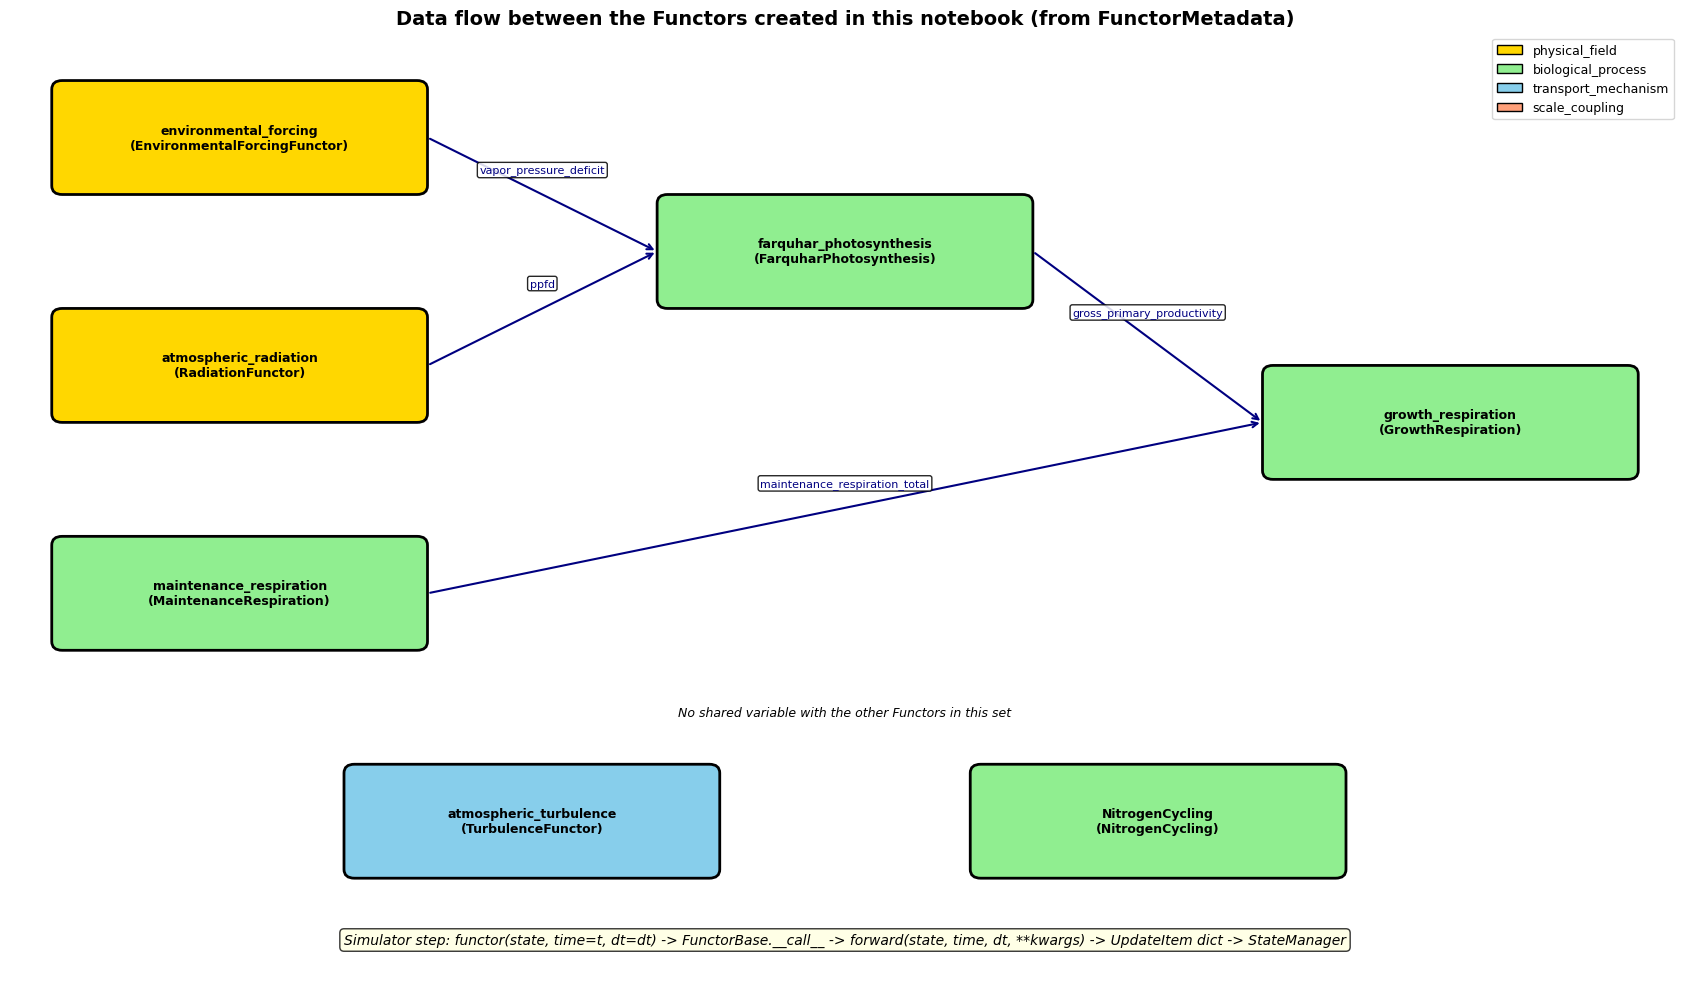

In [10]:
# === Functor data-flow diagram built from FunctorMetadata ===
# An edge A -> B is drawn when a variable in A.metadata.output_variables is also
# in B.metadata.input_variables. The Functor objects are the ones created above.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
%matplotlib inline

diagram_functors = [forcing_functor, radiation, turbulence, real_functor, maint_resp, growth_resp, n_cycle]
data_edges = []
for producer in diagram_functors:
    for consumer in diagram_functors:
        if producer is consumer:
            continue
        shared = sorted(set(producer.metadata.output_variables) & set(consumer.metadata.input_variables))
        if shared:
            data_edges.append((producer.name, consumer.name, shared))

print("Data edges from metadata:")
for producer_name, consumer_name, shared in data_edges:
    print(f"  {producer_name} -> {consumer_name}: {', '.join(shared)}")
print("Declared dependencies (get_dependencies):")
for functor in diagram_functors:
    print(f"  {functor.name}: {functor.get_dependencies()}")

# Column = longest data path from a source; Functors without an edge go to the bottom row.
connected = [f.name for f in diagram_functors if any(f.name in edge[:2] for edge in data_edges)]
column = {name: 0 for name in connected}
for _ in connected:
    for producer_name, consumer_name, _shared in data_edges:
        column[consumer_name] = max(column[consumer_name], column[producer_name] + 1)
unconnected = [f.name for f in diagram_functors if f.name not in column]


def column_x(col: int) -> float:
    return 2.2 + 5.8 * col


positions = {}
for row, name in enumerate([n for n in connected if column[n] == 0]):
    positions[name] = (column_x(0), 9.6 - 2.6 * row)
for col in sorted(c for c in set(column.values()) if c > 0):
    for name in [n for n in connected if column[n] == col]:
        producer_y = [positions[p][1] for p, c, _s in data_edges if c == name]
        y = sum(producer_y) / len(producer_y)
        while any(pos[0] == column_x(col) and abs(y - pos[1]) < 1.5 for pos in positions.values()):
            y -= 1.5
        positions[name] = (column_x(col), y)
for index, name in enumerate(unconnected):
    positions[name] = (5.0 + 6.0 * index, 1.8)

category_colors = {
    "physical_field": "#FFD700",
    "biological_process": "#90EE90",
    "transport_mechanism": "#87CEEB",
    "scale_coupling": "#FFA07A",
}
functor_by_name = {f.name: f for f in diagram_functors}
box_width, box_height = 3.4, 1.1

fig, ax = plt.subplots(figsize=(17, 10))
ax.set_xlim(0, 16.0)
ax.set_ylim(0, 10.8)
ax.axis("off")

for name, (x, y) in positions.items():
    functor = functor_by_name[name]
    ax.add_patch(mpatches.FancyBboxPatch(
        (x - box_width / 2, y - box_height / 2), box_width, box_height,
        boxstyle="round,pad=0.1", facecolor=category_colors[functor.metadata.category.value],
        edgecolor="black", lw=2,
    ))
    ax.text(x, y, f"{name}\n({type(functor).__name__})", ha="center", va="center",
            fontsize=9, fontweight="bold")

for producer_name, consumer_name, shared in data_edges:
    (x1, y1), (x2, y2) = positions[producer_name], positions[consumer_name]
    start, end = (x1 + box_width / 2 + 0.1, y1), (x2 - box_width / 2 - 0.1, y2)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="navy", lw=1.5))
    ax.text((start[0] + end[0]) / 2, (start[1] + end[1]) / 2 + 0.25, "\n".join(shared),
            ha="center", fontsize=8, color="navy",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85))

ax.text(8.0, 3.0, "No shared variable with the other Functors in this set", ha="center",
        fontsize=9, style="italic")
ax.legend(handles=[mpatches.Patch(facecolor=color, edgecolor="black", label=category)
                   for category, color in category_colors.items()], loc="upper right", fontsize=9)
ax.text(8.0, 0.4,
        "Simulator step: functor(state, time=t, dt=dt) -> FunctorBase.__call__ -> "
        "forward(state, time, dt, **kwargs) -> UpdateItem dict -> StateManager",
        ha="center", fontsize=10, style="italic",
        bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))
ax.set_title("Data flow between the Functors created in this notebook (from FunctorMetadata)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### PFT Parameterization Overview

> **Reference:** `docs/source/theory/pft_parameterization.md`

Plant Functional Type (PFT) parameters are configuration data in the parameter
database, one YAML file per PFT under
`relic/parameters/database/relic/biosphere/pft/` (namespace
`biosphere.pft.<pft>.*`). The ownership chain is ParameterManager ->
`PFTDefinition` -> `PFTRegistry` -> consuming Functor; PFT data are not a
Functor.

The next cell reads `photosynthesis.pathway`, `photosynthesis.vcmax25`,
`photosynthesis.jmax25`, `photosynthesis.g1` (Ball-Berry stomatal slope,
dimensionless) and `phenology.lai_max` for every PFT in the database through
the ParameterManager, prints them with their declared units, and plots them.
The notebook hard-codes no PFT value.

The table and figure report current database entries and declared units.
Counts and values are read on execution rather than copied from an old snapshot.

PFTs in the database: 15
PFT                              pathway    vcmax25    jmax25        g1   lai_max
broadleaf_deciduous_boreal       C3            65.0     130.0       9.0       6.0
broadleaf_deciduous_temperate    C3            65.0     130.0       9.0       6.0
broadleaf_deciduous_tropical     C3            65.0     130.0       9.0       6.0
broadleaf_evergreen_temperate    C3            65.0     130.0       9.0       6.0
broadleaf_evergreen_tropical     C3            65.0     130.0       9.0       6.0
c3_grass_arctic                  C3            65.0     130.0       9.0       6.0
c3_grass_temperate               C3            75.0     130.0       9.0       6.0
c4_grass_temperate               C4            54.0      80.0       9.0       6.0
crop_temperate                   C3            65.0     130.0       9.0       6.0
crop_tropical                    C3            65.0     130.0       9.0       6.0
needleleaf_deciduous_boreal      C3            65.0     130.0       9.0  

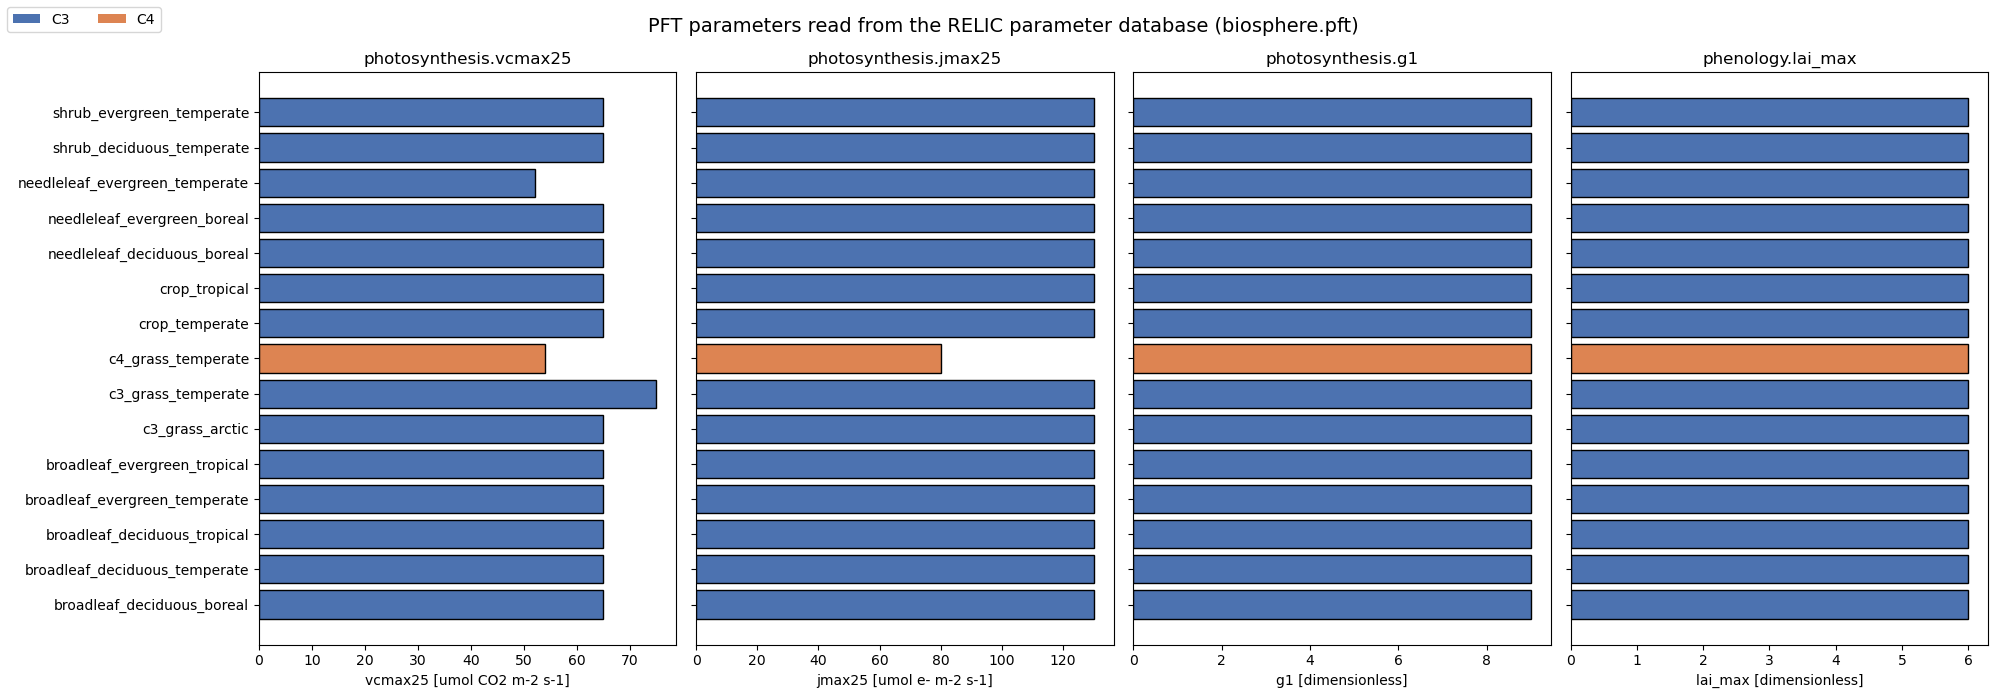

In [11]:
# === PFT Parameter Comparison (values read from the parameter database) ===
# Reference: docs/source/theory/pft_parameterization.md
# Non-Functor code reads parameters through get_global_manager() (manager, setup cell);
# get_namespace_parameters loads the namespace biosphere.pft as a whole.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

pft_specs = manager.get_namespace_parameters("biosphere.pft", return_specs=True)
vcmax_suffix = ".photosynthesis.vcmax25"
pft_names = sorted(
    key[len("biosphere.pft."):-len(vcmax_suffix)]
    for key in pft_specs
    if key.endswith(vcmax_suffix)
)
pft_fields = ["photosynthesis.vcmax25", "photosynthesis.jmax25", "photosynthesis.g1", "phenology.lai_max"]
pft_table = {
    pft: {field: pft_specs[f"biosphere.pft.{pft}.{field}"] for field in ["photosynthesis.pathway", *pft_fields]}
    for pft in pft_names
}
field_units = {field: pft_table[pft_names[0]][field].units for field in pft_fields}
for field, units in field_units.items():
    assert all(pft_table[pft][field].units == units for pft in pft_names), f"Mixed units for {field}"

print(f"PFTs in the database: {len(pft_names)}")
print(f"{'PFT':32s} {'pathway':8s} " + " ".join(f"{field.split('.')[-1]:>9s}" for field in pft_fields))
for pft in pft_names:
    row = pft_table[pft]
    values = " ".join(f"{float(row[field].value):9.1f}" for field in pft_fields)
    print(f"{pft:32s} {row['photosynthesis.pathway'].value:8s} {values}")
print("Units: " + ", ".join(f"{field.split('.')[-1]} [{units}]" for field, units in field_units.items()))

pathway_colors = {"C3": "#4C72B0", "C4": "#DD8452"}
bar_colors = [pathway_colors[pft_table[pft]["photosynthesis.pathway"].value] for pft in pft_names]
fig, axes = plt.subplots(1, len(pft_fields), figsize=(20, 7), sharey=True)
for ax, field in zip(axes, pft_fields):
    ax.barh(pft_names, [float(pft_table[pft][field].value) for pft in pft_names],
            color=bar_colors, edgecolor="black")
    ax.set_xlabel(f"{field.split('.')[-1]} [{field_units[field]}]")
    ax.set_title(field)
fig.legend(handles=[mpatches.Patch(facecolor=color, label=pathway)
                    for pathway, color in pathway_colors.items()], loc="upper left", ncol=2)
plt.suptitle("PFT parameters read from the RELIC parameter database (biosphere.pft)", fontsize=14)
plt.tight_layout()
plt.show()

---
## Structural Ecology Foundation

> **Reference:** `docs/source/theory/structural_ecology_foundation.md`

Structural ecology in RELIC is a governance layer on the existing orchestration
stack (`relic/orchestration/graph_ir.py`, `validator.py`, `compiler.py`); it adds
no solver and no execution path:

1. **Assertion triple** $\langle\phi, Op, Scope\rangle$: a predicate string, the
   node or protocol it applies to, and its scope, stored in the optional
   top-level `GraphIR.assertion` field.
2. **Well-formedness**: `validator._validate_assertion_payload` checks the
   assertion when the graph is validated (`validate_graph`, which the
   `compile_graph` path also runs).
3. **Operational coupling** ($Op$): resolved against a node id, a class type, an
   SSOT entry, the protocol list in `NodeDefinition.metadata` (`op_protocols` or
   `supported_ops`), or a built-in structural assertion op such as
   `iphs_structure_check`. A structural assertion op also requires a `context`
   mapping.
4. **Audit output**: `report.audit` (built by `build_audit_summary`) is the single
   audit payload of validation and compile results. Its `conservation_audit`
   summarizes the null space of the software graph and is not a physical
   conservation proof; physical budgets are checked on actual state changes
   through the StateManager ledgers.

### Assertion Schema

```json
{
  "assertion": {
    "phi": "predicate string",
    "op": "node id, class type, SSOT entry, protocol or structural op",
    "scope": "scale-name or scope-object",
    "context": {},
    "audit_key": "audit key"
  }
}
```

`phi`, `op` and `scope` are required; `context` and `audit_key` are optional,
and the validator reads no other key of an item. For a structural assertion
op, `audit_key` defaults to the canonical key of that op (for example
`iphs_audit` for `iphs_structure_check`), and a different value is reported as
an issue. Several items can be listed under `assertions`, `items` or `checks`.

---
## Surrogate Models in RELIC

> **Reference:** `docs/source/theory/surrogates.md`

A surrogate (emulator) replaces an expensive process calculation with a cheaper
approximation. RELIC implements:

1. **`SurrogateFunctor`** (`relic/models/surrogates.py`): abstract base for learned
   surrogates. It inherits `BiologicalProcessFunctor`, so a surrogate runs through
   the normal Functor lifecycle and its conservation checks. Subclasses implement
   `_load_model()` and `_predict()`.
2. **`ONNXSurrogate`** (`relic/models/surrogates.py`): runs an exported model with
   ONNX Runtime.
3. **`PyTorchSurrogate`** (`relic/models/pytorch_surrogate.py`): trainable PyTorch
   networks with MLP, ResNet or Transformer architectures.
4. **`SimpleCanopyPhotosynthesis`**
   (`relic/scientific/biosphere/surrogates/simple_photosynthesis.py`): a closed-form
   canopy GPP and ecosystem-respiration surrogate whose parameters are the
   `biosphere.photosynthesis.surrogate` namespace read in the setup cell. It is off by
   default; `create_standard_biosphere_functors(use_surrogate_photosynthesis=True)`
   puts it in place of `FarquharPhotosynthesis`.

The theory page also describes Gaussian-process emulators and physics-informed
neural networks (PINNs). `relic/models/surrogates.py` lists
`GaussianProcessSurrogate` and `PhysicsInformedSurrogate` as future
implementations; neither class exists. `PyTorchSurrogate` accepts an optional
`physics_loss` setting that adds penalty terms on the network outputs (declared
conservation ledger, smoothness, monotonicity, bounds) to its training loss, but
no RELIC surrogate adds the residual of a governing differential equation to its
loss, as a PINN does. RELIC has no gated blend of physics and surrogate outputs:
a process is computed either by its physics Functor or by a surrogate Functor.

In [12]:
output_dir = REPO_ROOT / "tutorial" / "primary" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "real_components_and_functors_summary.json"

result_payload = {
    "tutorial": "real_components_and_functors",
    "component_summary": component_summary,
    "simulation_summary": simulation_summary,
    "environmental_forcing_summary": environmental_forcing_summary,
    "functor_summary": simulator.get_functor_summary(),
    "provenance": provenance,
}
output_path.write_text(json.dumps(result_payload, indent=2), encoding="utf-8")

print(f"[OK] Output file = {output_path}")

result_payload

[OK] Output file = tutorial\primary\output\real_components_and_functors_summary.json


{'tutorial': 'real_components_and_functors',
 'component_summary': {'parameter_namespace': 'biosphere.photosynthesis.surrogate',
  'parameter_key_count': 8,
  'sample_parameter': {'key': 'biosphere.photosynthesis.surrogate.max_gpp_rate',
   'value': 2.5e-05,
   'units': 'kg C m-2 s-1'},
  'contract_registry': {'variable_count': 473,
   'domain_count': 4,
   'sample_contract': {'variable': 'soil_moisture',
    'units': 'm3 m-3',
    'owner': None,
    'writers': ['bucket_soil_moisture',
     'richards_soil_moisture',
     'soil_water_transport',
     'observation_state_feedback']}},
  'ssot_catalog': {'sample_entry': {'name': 'gross_primary_productivity',
    'standard_name': 'gross_primary_productivity',
    'units': 'kg C m-2 s-1',
    'spatial_basis': 'area_density'}},
  'cli': {'subcommands': ['compute',
    'data',
    'graph',
    'health',
    'healthcheck',
    'opt',
    'optimization',
    'orchestration',
    'params',
    'stoch',
    'stochastic']}},
 'simulation_summary': 

## Summary

This notebook reached the parameter database, the SCM variable contracts, the
SSOT variable catalog and the CLI from Python; ran the real
`FarquharPhotosynthesis` Functor for one step inside `RELICSimulator` with an
initial state whose units are all declared; listed the Functor registry; and
showed how real Functors are organized under the four abstraction pillars.
Each Functor's metadata declares its inputs, outputs, spatial scale and
variable kind; its execution dependencies come from `get_dependencies()`.

**Next:** NB03 calls the coupling and validation components directly:
`TimeStagger` for external component clocks, the `CouplingCapabilityRegistry`,
the `HealthChecker` and the conservation ledger. Dependency edges between
Functors and the topological execution order are shown in NB10.